# Phase 4: Baseline models (FD001)

**Goal:** find out how well simple models predict remaining life on NASA's official test engines. Every later model (Phase 5 deep learning) has to beat these numbers, by more than chance, to earn its place.

Training and scoring happen in `models/baselines.py`; this notebook reads its saved results. `python -m models.verify_baselines` rechecks every number independently (21/21 checks), and `python -m models.report_phase4` writes `docs/MODEL_METRICS.md` straight from the results so the document cannot drift.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "docs" / "figures"
sns.set_theme(style="whitegrid")

res = json.loads((ROOT / "models/results_phase4.json").read_text())
preds = pd.read_csv(ROOT / "models/predictions_phase4.csv")
imp = pd.read_csv(ROOT / "models/importance_phase4.csv")
print(res["protocol"])

settings chosen on 20 validation engines; refit on all 100 training engines; test set scored once at each engine's last observed cycle; true RUL capped at 125


## 4.1 The protocol: why the test set is touched only once

**Concept:** settings (Ridge's penalty, XGBoost's tree depth and number of trees) are chosen on the **20 validation engines**. Each model is then refit on **all 100 training engines** and scored **once** on the **100 test engines**, at each engine's last observed cycle.

**Why:** if you keep adjusting a model until the test score looks good, the test score stops being an honest estimate. Using it once keeps it honest.

## 4.2 The two metrics

- **RMSE**: the typical prediction error, in cycles.
- **PHM08 score** (NASA's): with d = predicted - true, a *late* prediction (d > 0, the engine fails sooner than predicted) costs e^(d/10) - 1, while an *early* one costs e^(-d/13) - 1. Late errors are punished more because they mean an in-service failure.

True RUL is capped at 125 for scoring, the same cap used in training. The results file also reports scores against NASA's uncapped values.

In [2]:
rows = []
for name, r in res["models"].items():
    rows.append({"model": name, "validation RMSE": r["val_rmse"], "test-like validation RMSE": r["val_rmse_testlike"],
                 "test RMSE": r["rmse"],
                 "95% interval": f"{r['rmse_ci95'][0]:.1f}-{r['rmse_ci95'][1]:.1f}", "MAE": r["mae"],
                 "PHM08": r["phm"], "late predictions": f"{r['late_share']:.0%}",
                 "seed spread (sd)": r.get("seed_test_rmse_std", np.nan)})
table = pd.DataFrame(rows).round(2)
table

,model,validation RMSE,test-like validation RMSE,test RMSE,95% interval,MAE,PHM08,late predictions,seed spread (sd)
0,Fleet average,41.72,43.36,41.94,37.4-46.3,34.83,33354.47,50%,NaN
1,Age only (cycle count),26.76,31.30,31.20,27.3-35.0,25.14,3514.23,56%,NaN
2,"Ridge, raw sensors (14)",19.90,19.89,20.59,17.8-23.3,16.37,1223.93,58%,NaN
3,"Ridge, all 168 features",16.27,16.76,16.28,14.0-18.4,12.96,464.68,51%,NaN
4,"XGBoost, all 168 features",13.27,14.58,15.38,12.4-18.2,11.02,587.73,54%,0.20
5,"XGBoost, no FFT (154)",13.58,15.17,15.87,12.8-19.0,11.30,557.78,59%,0.31
6,"XGBoost, rolling only, no EMA/FFT (140)",13.61,15.21,15.68,12.8-18.6,11.36,522.74,59%,0.13
7,"XGBoost, without s9 and s14 (144)",13.96,15.34,15.51,12.5-18.4,11.03,561.26,58%,0.21
8,"XGBoost, raw sensors only (14)",16.83,18.44,17.36,14.0-20.5,12.21,1037.64,55%,0.25


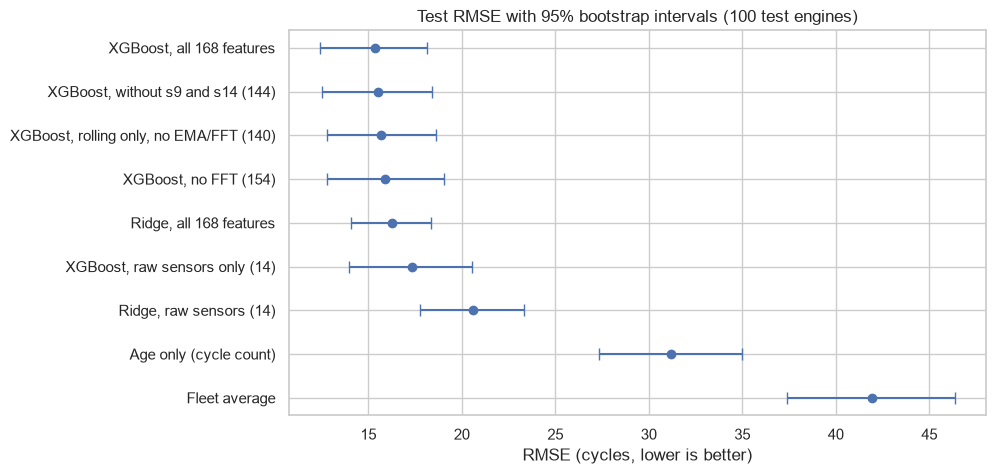

In [3]:
t = pd.DataFrame([{"model": n, "rmse": r["rmse"], "lo": r["rmse_ci95"][0], "hi": r["rmse_ci95"][1]}
                  for n, r in res["models"].items()]).sort_values("rmse")
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(t.rmse, t.model, xerr=[t.rmse - t.lo, t.hi - t.rmse], fmt="o", color="#4C72B0", capsize=4)
ax.invert_yaxis()
ax.set(title="Test RMSE with 95% bootstrap intervals (100 test engines)", xlabel="RMSE (cycles, lower is better)")
fig.savefig(FIG / "fd001_baselines_rmse.png", dpi=150, bbox_inches="tight")

**Two baselines with no sensors at all:** the *fleet average* predicts one number for every engine; *age only* predicts from the cycle count alone (the average remaining life of training engines at that same cycle). A sensor model has to beat both to show it reads wear, not just age.

**Test-like validation:** the plain validation score uses every cycle of the 20 validation engines, and 39% of those sit at the easy 125 cap. The *test-like* score keeps only readings that look like the test set (at least 31 cycles observed, true RUL at most 145), so it is closer to what the test measures.

## 4.3 Choosing the published model on validation only

**Concept:** the model that goes forward must be chosen **before** looking at the test set. Here the choice is made on the 20 validation engines, comparing models where it matters (near failure) and on test-like readings.

**Why:** if the test set decides which model is published, its score is no longer an honest estimate. Because each validation engine contributes many readings, the bootstrap resamples **whole engines**, not rows (rows from the same engine are not independent).

In [4]:
sel = []
for name, c in res["model_selection_on_validation"].items():
    for key, label in (("val_near_failure_mae", "MAE, readings with <= 50 cycles left"), ("val_testlike_rmse", "RMSE, test-like readings")):
        lo, hi = c[key]["ci"]
        sel.append({"comparison on validation": name, "measure": label, "gap A - B": round(c[key]["diff"], 2),
                    "95% interval": f"{lo:+.2f} to {hi:+.2f}", "verdict": "A better" if hi < 0 else "no clear difference"})
pd.DataFrame(sel)

,comparison on validation,measure,gap A - B,95% interval,verdict
0,"XGBoost, all 168 features vs Ridge, all 168 fe...","MAE, readings with <= 50 cycles left",-6.43,-8.06 to -4.89,A better
1,"XGBoost, all 168 features vs Ridge, all 168 fe...","RMSE, test-like readings",-2.18,-4.00 to -0.66,A better
2,"XGBoost, all 168 features vs Age only (cycle c...","MAE, readings with <= 50 cycles left",-25.18,-29.89 to -20.58,A better
3,"XGBoost, all 168 features vs Age only (cycle c...","RMSE, test-like readings",-16.72,-21.40 to -12.16,A better


## 4.4 Is a gap on the test set real, or luck?

**Concept:** a *paired bootstrap* resamples the same 100 test engines thousands of times and recomputes the gap between two models each time. If the 95% interval of the gap excludes 0, the difference is real; if it includes 0, the test set cannot tell the two models apart.

**Why:** with only 100 test engines, a 1-cycle difference in RMSE can easily be luck. Claiming one model is better without this check is the most common overclaim in student ML projects.

**Holm correction:** nine comparisons are tested at once, so one could look significant by chance. Holm's method raises the bar for each comparison in turn; a gap counts as real only if its Holm-adjusted p-value is below 0.05.

In [5]:
comp = []
for name, c in res["paired_comparisons"].items():
    for metric in ("rmse", "phm"):
        lo, hi = c[metric]["ci"]
        comp.append({"comparison (A vs B)": name, "metric": metric.upper(), "gap A - B": round(c[metric]["diff"], 2),
                     "95% interval": f"{lo:+.2f} to {hi:+.2f}", "Holm p": round(c[metric]["p_holm"], 3),
                     "verdict": ("A better" if c[metric]["diff"] < 0 else "B better") if c[metric]["significant"] else "no clear difference"})
pd.DataFrame(comp)

,comparison (A vs B),metric,gap A - B,95% interval,Holm p,verdict
0,"XGBoost, all 168 features vs Fleet average",RMSE,-26.56,-32.77 to -20.63,0.005,A better
1,"XGBoost, all 168 features vs Fleet average",PHM,-32766.74,-46963.87 to -20066.53,0.005,A better
2,"XGBoost, all 168 features vs Age only (cycle c...",RMSE,-15.82,-20.58 to -11.01,0.005,A better
3,"XGBoost, all 168 features vs Age only (cycle c...",PHM,-2926.50,-4759.44 to -1398.79,0.005,A better
4,"XGBoost, all 168 features vs Ridge, raw sensor...",RMSE,-5.21,-8.64 to -1.93,0.005,A better
5,"XGBoost, all 168 features vs Ridge, raw sensor...",PHM,-636.20,-1714.86 to +139.30,0.670,no clear difference
6,"XGBoost, all 168 features vs Ridge, all 168 fe...",RMSE,-0.90,-2.81 to +0.95,1.000,no clear difference
7,"XGBoost, all 168 features vs Ridge, all 168 fe...",PHM,123.05,-111.38 to +473.31,1.000,no clear difference
8,"XGBoost, all 168 features vs XGBoost, no FFT (...",RMSE,-0.50,-1.79 to +0.57,1.000,no clear difference
9,"XGBoost, all 168 features vs XGBoost, no FFT (...",PHM,29.95,-195.69 to +279.71,1.000,no clear difference


## 4.5 Where the errors are

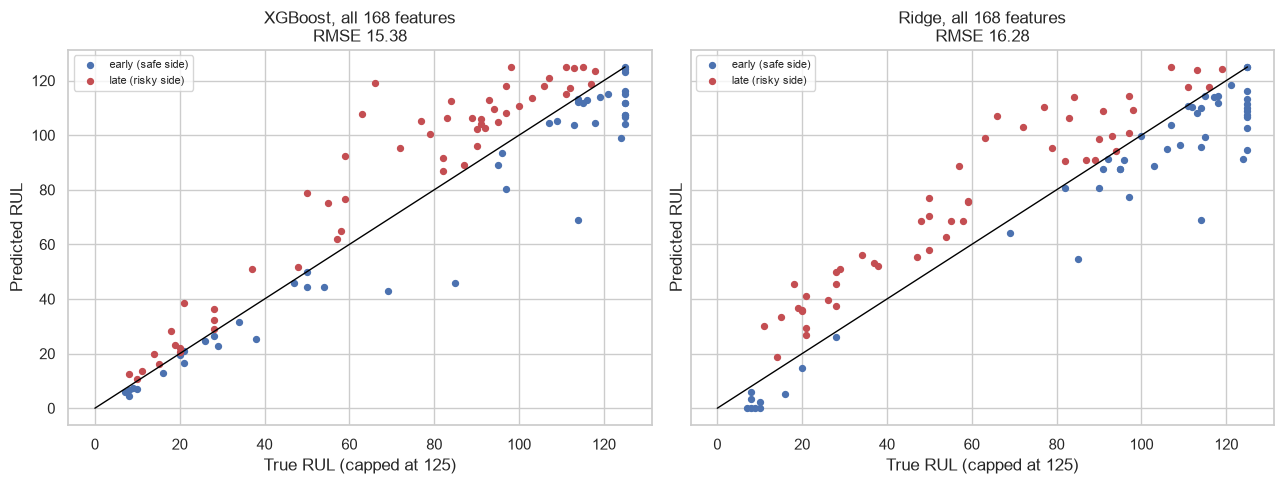

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, m in zip(axes, ["XGBoost, all 168 features", "Ridge, all 168 features"]):
    late = preds[m] > preds.RUL
    ax.scatter(preds.RUL[~late], preds[m][~late], s=18, label="early (safe side)", color="#4C72B0")
    ax.scatter(preds.RUL[late], preds[m][late], s=18, label="late (risky side)", color="#C44E52")
    ax.plot([0, 125], [0, 125], color="black", linewidth=1)
    ax.set(title=f"{m}\nRMSE {res['models'][m]['rmse']:.2f}", xlabel="True RUL (capped at 125)", ylabel="Predicted RUL")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fd001_baselines_pred_vs_true.png", dpi=150, bbox_inches="tight")

In [7]:
m = "XGBoost, all 168 features"
err = (preds[m] - preds.RUL).abs()
bands = pd.cut(preds.RUL, [0, 25, 50, 75, 100, 125], include_lowest=True)
pd.DataFrame({"engines": err.groupby(bands, observed=False).size(),
              "mean absolute error": err.groupby(bands, observed=False).mean().round(1)})

,engines,mean absolute error
RUL,,
"(-0.001, 25.0]",19,3.6
"(25.0, 50.0]",14,6.5
"(50.0, 75.0]",10,24.0
"(75.0, 100.0]",24,15.5
"(100.0, 125.0]",33,10.0


### Near failure, where maintenance decisions are made

Overall scores mix healthy and worn engines. Validation already showed XGBoost is clearly better near failure (section 4.3); this checks that the test set agrees, on the 33 test engines with 50 or fewer cycles left.

In [8]:
from models.metrics import mae, paired_bootstrap
near = preds.RUL <= 50
rows = []
for m in ["XGBoost, all 168 features", "Ridge, all 168 features"]:
    d = preds[m][near] - preds.RUL[near]
    rows.append({"model": m, "engines": int(near.sum()), "MAE": round(d.abs().mean(), 1),
                 "mean signed error (+ = late)": round(d.mean(), 1), "late share": f"{(d > 0).mean():.0%}"})
display(pd.DataFrame(rows))
c = paired_bootstrap(preds.RUL[near], preds["XGBoost, all 168 features"][near], preds["Ridge, all 168 features"][near], metric=mae)
print(f"MAE gap XGBoost - Ridge: {c['diff']:+.1f} cycles, 95% interval {c['ci'][0]:+.1f} to {c['ci'][1]:+.1f}, XGBoost better in {c['a_wins']:.0%} of resamples")

,model,engines,MAE,mean signed error (+ = late),late share
0,"XGBoost, all 168 features",33,4.8,1.8,48%
1,"Ridge, all 168 features",33,13.3,9.3,70%


MAE gap XGBoost - Ridge: -8.5 cycles, 95% interval -10.9 to -6.3, XGBoost better in 100% of resamples


['s4_ema', 's4_mean10', 's15_mean10', 's4_mean5', 's11_mean10', 's11_mean5', 's2_mean10', 's15_mean5', 's3_ema', 's9_mean5', 's9_mean10', 's11_ema', 's9_ema', 's3_mean10', 's15_ema']


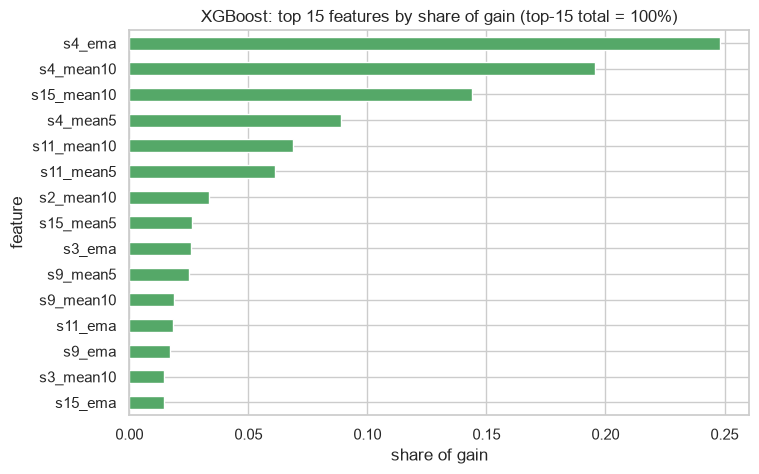

In [9]:
top = imp.head(15).set_index("feature")["gain"]
fig, ax = plt.subplots(figsize=(8, 5))
(top / top.sum())[::-1].plot.barh(ax=ax, color="#55A868")
ax.set(title="XGBoost: top 15 features by share of gain (top-15 total = 100%)", xlabel="share of gain")
fig.savefig(FIG / "fd001_xgb_importance.png", dpi=150, bbox_inches="tight")
print(top.index.tolist())

## What the results say

1. **Feature engineering is the big win, and it is real.** The same linear model goes from 20.59 to 16.28 RMSE when given the Phase 3 features (gap -4.31, Holm-adjusted p 0.005; also significant on PHM08).
2. **Sensors carry far more than age.** Age alone scores 31.20 RMSE, better than the fleet average (41.94) but twice XGBoost's error.
3. **Over all 100 test engines, XGBoost and Ridge on the same features are statistically tied** (RMSE gap -0.90, interval -2.81 to +0.95; Ridge even has the better PHM08, also not significant).
4. **XGBoost was chosen on validation, and the test set agrees.** On the 20 validation engines it beats Ridge near failure (MAE gap -6.43, interval -8.06 to -4.89, whole engines resampled) and on test-like readings (-2.18). On test, near failure, its MAE is 4.8 cycles against Ridge's 13.3, and Ridge runs late by +9.3 cycles on average (the dangerous direction). The test result holds at every cut-off from 25 to 75 cycles left.
5. **FFT, EMA and s9/s14 have no measurable effect.** Removing any of them changes RMSE by 0.1-0.5 cycles, inside the test noise and close to XGBoost's own seed-to-seed spread (about 0.2). They are kept, and this is stated.
6. **Holm correction removed one claim.** Without it, "XGBoost beats raw-sensor XGBoost on PHM08" looked significant; tested together with the other comparisons it is not (Holm p 0.12).
7. **Validation, test-like validation and test agree in order.** XGBoost scores 13.27 on all validation rows, 14.58 on test-like rows and 15.38 on test: the test-like view explains most of the gap.
8. **Most accurate where it matters most:** XGBoost's MAE is 3.6 cycles for engines within 25 cycles of failure and 6.5 for 26-50; the largest errors (24.0) are mid-life, 51-75 cycles left.
9. **The bar for Phase 5:** beat **15.38 RMSE and 588 PHM08** with a paired, Holm-corrected test that excludes 0, and stay at least as accurate near failure.

## Why we did these tasks

| # | Task | Why we did it | What we learned | What it changes next |
| --- | --- | --- | --- | --- |
| 1 | Fixed the protocol: tune on validation, refit on all training engines, test once | Re-using the test set to tune makes its score dishonest | Every setting is the minimum of a validation search, checked independently | Phase 5 follows the same protocol |
| 2 | Chose the published model on validation, resampling whole engines | Picking the winner from test results would leak the test set into the choice | XGBoost wins near failure on validation (-6.4 MAE); test confirms (-8.5) | Phase 5 must also be chosen on validation |
| 3 | Used RMSE and the PHM08 score | RMSE treats early and late errors alike; maintenance does not | Rankings can differ by metric: Ridge has the better overall PHM08 | Every later model is reported on both |
| 4 | Fleet-average and age-only baselines | Show what you get with no sensors, and with age only | 41.9 and 31.2 RMSE: sensors add a lot beyond age | Confirms the models read wear, not just time |
| 5 | Ridge on raw sensors vs on 168 features | Separates the value of features from model power | Features alone cut RMSE by 4.3 cycles, a real gap | Phase 3 is justified with evidence |
| 6 | XGBoost with 5 seeds, depth search on two validation views | Shows chance variation; checks the depth choice is robust | Seed spread 0.2; depth 5 wins on both views | Phase 5 reports seed spread too |
| 7 | Ablations: no FFT, no EMA, no s9/s14, raw only | Phase 3 left open whether these features help | None changes accuracy measurably | Feature set stays; stated honestly |
| 8 | Paired bootstrap with Holm correction | 100 engines is small and 9 comparisons are tested at once | One earlier claim did not survive the correction | All later claims use the same correction |
| 9 | Pinned the NASA files by checksum; CI downloads them and runs every verifier | Results must reproduce on a clean machine, on byte-identical data | Verification no longer depends on my laptop | Every push re-proves the published numbers |
| 10 | Independent verification (21/21) and a generated metrics document | Resume numbers must be exactly reproducible and match the docs | Caught a float32 mismatch, a shadowed variable and a Holm tie bug | Every phase keeps a verifier and generated docs |

**The habit to keep:** a model is "better" only if the gap survives a fair test on the same engines. Otherwise, report a tie.